In [1]:
# -*- coding: utf-8 -*-
"""Bước 1: đọc tệp dữ liệu và nhìn qua một lượt.

Chú thích trong tệp viết tiếng Việt có dấu, nhưng phần in ra màn hình cố ý
viết không dấu. Cửa sổ lệnh Windows thường không hiện được chữ có dấu.
"""

import pandas as pd

# Đọc tệp CSV thành một bảng. Tên df là viết tắt quen dùng của data frame.
df = pd.read_csv("data/gia_nha.csv")

print("Kich thuoc bang (so dong, so cot):", df.shape)
print()

print("Nam dong dau tien:")
print(df.head())
print()

print("Ten cac cot:", list(df.columns))
print()

print("Thong ke nhanh cot dien_tich va cot gia:")
print(df[["dien_tich", "gia"]].describe().round(2))
print()

print("So o bi thieu trong tung cot:")
print(df.isna().sum())


Kich thuoc bang (so dong, so cot): (60, 4)

Nam dong dau tien:
   dien_tich  so_phong  tuoi_nha   gia
0       35.5         1        18  3.00
1       37.6         2         7  3.87
2       49.4         2        20  4.25
3       49.0         2        16  4.60
4       49.9         1        12  3.99

Ten cac cot: ['dien_tich', 'so_phong', 'tuoi_nha', 'gia']

Thong ke nhanh cot dien_tich va cot gia:
       dien_tich    gia
count      60.00  60.00
mean       77.73   6.49
std        20.22   1.64
min        35.50   3.00
25%        63.02   5.16
50%        75.10   6.40
75%        91.88   7.70
max       117.50   9.74

So o bi thieu trong tung cot:
dien_tich    0
so_phong     0
tuoi_nha     0
gia          0
dtype: int64


# Bài tập 1: Lọc ra nhóm căn hộ lớn


In [2]:
import pandas as pd

# 1. Đọc bộ dữ liệu
df = pd.read_csv("data/gia_nha.csv")

# 2. Lọc các căn hộ có diện tích lớn hơn 100 m² (dùng boolean mask)
nhom_lon = df[df["dien_tich"] > 100]

# 3. Tính số lượng căn và giá bán trung bình của nhóm
so_luong = len(nhom_lon)
gia_trung_binh = nhom_lon["gia"].mean()

# 4. In ra hai con số kết quả theo yêu cầu
print("Số căn có diện tích > 100 m²:", so_luong)
print(f"Giá trung bình của nhóm căn hộ lớn (> 100 m²): {gia_trung_binh:.4f} tỷ đồng")

# 5. Nhận xét bằng lời
print("\nNhận xét:")
print(f"- Trong tổng số 60 căn hộ của bộ dữ liệu, có {so_luong} căn có diện tích lớn hơn 100 m² (chiếm {so_luong/len(df)*100:.1f}%).")
print(f"- Mức giá trung bình của nhóm căn hộ lớn này là {gia_trung_binh:.4f} tỷ đồng, cao hơn rõ rệt so với mức giá trung bình của toàn bộ 60 căn (6.49 tỷ đồng).")
print("- Điều này hoàn toàn phù hợp với thực tế thị trường: diện tích sàn càng rộng thì tổng giá trị căn nhà càng lớn.")


Số căn có diện tích > 100 m²: 10
Giá trung bình của nhóm căn hộ lớn (> 100 m²): 8.9620 tỷ đồng

Nhận xét:
- Trong tổng số 60 căn hộ của bộ dữ liệu, có 10 căn có diện tích lớn hơn 100 m² (chiếm 16.7%).
- Mức giá trung bình của nhóm căn hộ lớn này là 8.9620 tỷ đồng, cao hơn rõ rệt so với mức giá trung bình của toàn bộ 60 căn (6.49 tỷ đồng).
- Điều này hoàn toàn phù hợp với thực tế thị trường: diện tích sàn càng rộng thì tổng giá trị căn nhà càng lớn.


# Bài tập 2: Vẽ biểu đồ phân tán theo số phòng


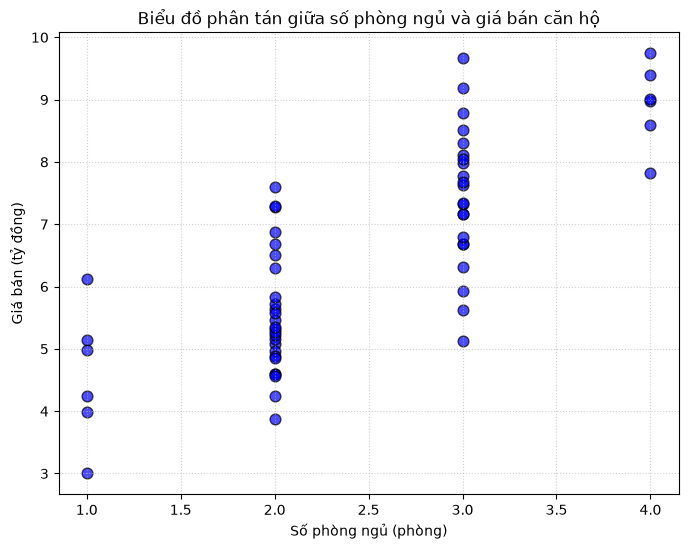

Nhận xét:
- Biểu đồ cho thấy xu hướng đồng biến rõ rệt: số lượng phòng ngủ càng nhiều thì giá bán căn hộ càng cao.
- Căn 1 phòng ngủ có giá tập trung trong khoảng 3 - 4 tỷ đồng, trong khi căn 4 phòng ngủ có giá từ 7.5 đến gần 10 tỷ đồng.
- Tuy nhiên, với các căn có cùng số phòng (ví dụ cùng 2 phòng), giá vẫn có sự chênh lệch đáng kể do diện tích và tuổi nhà khác nhau.


In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Đọc bộ dữ liệu
df = pd.read_csv("data/gia_nha.csv")

# 2. Vẽ biểu đồ phân tán giữa số phòng (so_phong) và giá nhà (gia)
plt.figure(figsize=(8, 6))
plt.scatter(df["so_phong"], df["gia"], color="blue", alpha=0.7, edgecolors="k", s=60)

# 3. Đặt tên cho hai trục và đặt tiêu đề cho hình
plt.xlabel("Số phòng ngủ (phòng)")
plt.ylabel("Giá bán (tỷ đồng)")
plt.title("Biểu đồ phân tán giữa số phòng ngủ và giá bán căn hộ")
plt.grid(True, linestyle=":", alpha=0.6)

# 4. Lưu hình thành tệp bai2.png trước khi gọi plt.show()
plt.savefig("bai2.png", dpi=150, bbox_inches="tight")
plt.show()

# 5. Nhận xét về xu hướng nhìn thấy (đặt trong lệnh print)
print("Nhận xét:")
print("- Biểu đồ cho thấy xu hướng đồng biến rõ rệt: số lượng phòng ngủ càng nhiều thì giá bán căn hộ càng cao.")
print("- Căn 1 phòng ngủ có giá tập trung trong khoảng 3 - 4 tỷ đồng, trong khi căn 4 phòng ngủ có giá từ 7.5 đến gần 10 tỷ đồng.")
print("- Tuy nhiên, với các căn có cùng số phòng (ví dụ cùng 2 phòng), giá vẫn có sự chênh lệch đáng kể do diện tích và tuổi nhà khác nhau.")


# Bài tập 3: Đổi biến đầu vào sang tuổi nhà


Hệ số góc w = -0.037858
Hệ số chặn b = 6.983593


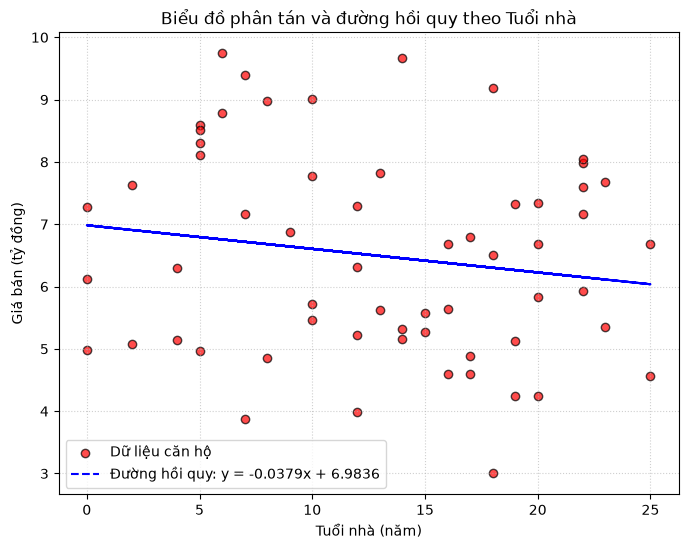


--- NHẬN XÉT VÀ GIẢI THÍCH CHI TIẾT ---
1. Nhận xét dấu: Hệ số góc w mang dấu âm (w = -0.037858).
2. Giải thích vì sao w mang dấu âm:
   - Hệ số w = -0.037858 cho biết cứ mỗi năm tuổi nhà tăng thêm, giá bán trung bình sẽ giảm khoảng 37.86 triệu đồng.
   - Dấu âm thể hiện quan hệ nghịch biến rất hợp lý: nhà càng cũ thì chất lượng công trình, hạ tầng nội thất
     càng bị hao mòn theo thời gian, dẫn đến giá trị thẩm mỹ và giá trị sử dụng giảm dần.
3. Trả lời câu hỏi thêm (độ tin cậy của w và quan hệ chặt chẽ):
   - Quan sát biểu đồ phân tán ta thấy các điểm dữ liệu KHÔNG bám sát quanh đường thẳng như ở biểu đồ diện tích,
     mà nằm phân tán rải rác rất rộng ở mọi mức tuổi nhà.
   - Do đó, con số w này có độ tin cậy rất thấp trong việc dự đoán giá (sai số MSE rất lớn, R² thấp).
   - Kết luận quan trọng: Một hệ số có dấu đúng theo trực giác CHƯA ĐỦ để kết luận hai đại lượng có quan hệ chặt chẽ.
     Cần phải kiểm tra thêm độ tản mát của dữ liệu quanh đường hồi quy và chỉ số R² trước khi 

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Đọc bộ dữ liệu
df = pd.read_csv("data/gia_nha.csv")

# 2. Trích xuất biến đầu vào x (tuoi_nha) và biến mục tiêu y (gia)
x = df["tuoi_nha"].to_numpy()
y = df["gia"].to_numpy()

# 3. Tính giá trị trung bình
x_tb = x.mean()
y_tb = y.mean()

# 4. Áp dụng công thức bình phương tối thiểu (OLS) ở mục 5
tu_so = ((x - x_tb) * (y - y_tb)).sum()
mau_so = ((x - x_tb) ** 2).sum()

w = tu_so / mau_so
b = y_tb - w * x_tb

# 5. In ra hệ số góc w và hệ số chặn b với 6 chữ số sau dấu phẩy
print(f"Hệ số góc w = {w:.6f}")
print(f"Hệ số chặn b = {b:.6f}")

# 6. Vẽ biểu đồ phân tán và đường hồi quy để đối chiếu (câu hỏi thêm)
plt.figure(figsize=(8, 6))
plt.scatter(df["tuoi_nha"], df["gia"], color="red", alpha=0.7, edgecolors="k", label="Dữ liệu căn hộ")
plt.plot(x, w * x + b, color="blue", linestyle="--", label=f"Đường hồi quy: y = {w:.4f}x + {b:.4f}")
plt.xlabel("Tuổi nhà (năm)")
plt.ylabel("Giá bán (tỷ đồng)")
plt.title("Biểu đồ phân tán và đường hồi quy theo Tuổi nhà")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.savefig("bai3_tuoi_nha.png", dpi=150, bbox_inches="tight")
plt.show()

# 7. Nhận xét dấu của w và giải thích bằng lời
print("\n--- NHẬN XÉT VÀ GIẢI THÍCH CHI TIẾT ---")
print(f"1. Nhận xét dấu: Hệ số góc w mang dấu âm (w = {w:.6f}).")
print("2. Giải thích vì sao w mang dấu âm:")
print(f"   - Hệ số w = {w:.6f} cho biết cứ mỗi năm tuổi nhà tăng thêm, giá bán trung bình sẽ giảm khoảng {-w*1000:.2f} triệu đồng.")
print("   - Dấu âm thể hiện quan hệ nghịch biến rất hợp lý: nhà càng cũ thì chất lượng công trình, hạ tầng nội thất")
print("     càng bị hao mòn theo thời gian, dẫn đến giá trị thẩm mỹ và giá trị sử dụng giảm dần.")
print("3. Trả lời câu hỏi thêm (độ tin cậy của w và quan hệ chặt chẽ):")
print("   - Quan sát biểu đồ phân tán ta thấy các điểm dữ liệu KHÔNG bám sát quanh đường thẳng như ở biểu đồ diện tích,")
print("     mà nằm phân tán rải rác rất rộng ở mọi mức tuổi nhà.")
print("   - Do đó, con số w này có độ tin cậy rất thấp trong việc dự đoán giá (sai số MSE rất lớn, R² thấp).")
print("   - Kết luận quan trọng: Một hệ số có dấu đúng theo trực giác CHƯA ĐỦ để kết luận hai đại lượng có quan hệ chặt chẽ.")
print("     Cần phải kiểm tra thêm độ tản mát của dữ liệu quanh đường hồi quy và chỉ số R² trước khi đưa ra kết luận.")


# Bài tập 4: Thêm số phòng vào mô hình


In [5]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

# 1. Đọc dữ liệu
df = pd.read_csv("data/gia_nha.csv")

# 2. Huấn luyện với hai cột đầu vào là dien_tich và so_phong
X = df[["dien_tich", "so_phong"]]
y = df["gia"]

# 3. Chia tập học và kiểm tra (giữ nguyên test_size=0.2 và random_state=42 để công bằng)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Khớp mô hình hồi quy tuyến tính
mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

# 5. Dự đoán trên tập kiểm tra và tính R²
y_pred = mo_hinh.predict(X_test)
r2_hai_bien = r2_score(y_test, y_pred)

# 6. In kết quả và so sánh với mô hình một biến
print(f"R² trên tập kiểm tra (mô hình 2 biến: dien_tich + so_phong): {r2_hai_bien:.4f}")
print(f"R² trên tập kiểm tra (mô hình 1 biến: dien_tich)          : 0.9622")
print(f"Mức chênh lệch R²                                          : +{r2_hai_bien - 0.9622:.4f}")

# 7. Nhận xét và đánh giá xem thêm cột có đáng không
print("\n--- SO SÁNH VÀ ĐÁNH GIÁ ---")
print("Nhận xét:")
print(f"- R² tăng từ 0.9622 lên {r2_hai_bien:.4f}, tức giải thích thêm được khoảng {(r2_hai_bien - 0.9622)*100:.2f}% biến động giá.")
print("- Việc thêm cột so_phong là CÓ ĐÁNG vì:")
print("  1. Cải thiện được độ chính xác dự báo (R² tăng lên gần 0.97).")
print("  2. Số phòng ngủ mang thông tin thực tế về công năng sử dụng của căn hộ, bổ sung cho diện tích sàn.")
print("  3. Tuy nhiên mức tăng không quá lớn (khoảng 0.76%) vì diện tích và số phòng vốn đi kèm khá chặt với nhau,")
print("     diện tích đã gánh phần lớn năng lực giải thích giá bán.")


R² trên tập kiểm tra (mô hình 2 biến: dien_tich + so_phong): 0.9698
R² trên tập kiểm tra (mô hình 1 biến: dien_tich)          : 0.9622
Mức chênh lệch R²                                          : +0.0076

--- SO SÁNH VÀ ĐÁNH GIÁ ---
Nhận xét:
- R² tăng từ 0.9622 lên 0.9698, tức giải thích thêm được khoảng 0.76% biến động giá.
- Việc thêm cột so_phong là CÓ ĐÁNG vì:
  1. Cải thiện được độ chính xác dự báo (R² tăng lên gần 0.97).
  2. Số phòng ngủ mang thông tin thực tế về công năng sử dụng của căn hộ, bổ sung cho diện tích sàn.
  3. Tuy nhiên mức tăng không quá lớn (khoảng 0.76%) vì diện tích và số phòng vốn đi kèm khá chặt với nhau,
     diện tích đã gánh phần lớn năng lực giải thích giá bán.


# Bài tập 5: Thử hai tốc độ học khác


In [6]:
import numpy as np
import pandas as pd

# 1. Đọc dữ liệu
df = pd.read_csv("data/gia_nha.csv")
x_goc = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

# 2. Chuẩn hóa diện tích về thang đo nhỏ quanh 0 (giống b6_gradient_descent.py)
x_tb = x_goc.mean()
x_do_lech = x_goc.std()
x = (x_goc - x_tb) / x_do_lech
n = len(x)

# 3. Hàm Gradient Descent giữ nguyên cấu trúc chuẩn của b6_gradient_descent.py
def chay_gradient_descent(toc_do_hoc, so_vong=200):
    w, b = 0.0, 0.0
    for vong in range(1, so_vong + 1):
        y_du_doan = w * x + b
        chenh_lech = y_du_doan - y
        grad_w = (2 / n) * (chenh_lech * x).sum()
        grad_b = (2 / n) * chenh_lech.sum()
        w -= toc_do_hoc * grad_w
        b -= toc_do_hoc * grad_b
    # Tính lại MSE bằng w và b VỪA cập nhật tại vòng lặp thứ 200
    mse_200 = (((w * x + b) - y) ** 2).mean()
    return mse_200

# 4. Chạy với hai tốc độ học theo yêu cầu
mse_0001 = chay_gradient_descent(0.001, so_vong=200)
mse_102 = chay_gradient_descent(1.02, so_vong=200)

print(f"Giá trị MSE ở vòng lặp thứ 200 với tốc độ học 0.001 : {mse_0001:.4f}")
print(f"Giá trị MSE ở vòng lặp thứ 200 với tốc độ học 1.02  : {mse_102:.4e}")

# 5. Giải thích chi tiết vì sao hai con số đó khác nhau
print("\n--- GIẢI THÍCH CHI TIẾT VÌ SAO HAI CON SỐ KHÁC NHAU ---")
print("1. Với tốc độ học = 0.001 (Quá nhỏ):")
print("   - Bước chân mỗi vòng lặp quá ngắn (như người xuống núi bằng bước 1 cm).")
print(f"   - Sau 200 vòng lặp, thuật toán vẫn còn ở lưng chừng dốc và chưa kịp đi tới đáy (MSE còn {mse_0001:.4f}, rất xa mức tối ưu 0.1790).")
print("   - Muốn tới đáy với tốc độ này thì phải chạy hàng nghìn vòng, gây tốn thời gian tính toán không cần thiết.")
print("\n2. Với tốc độ học = 1.02 (Quá lớn):")
print("   - Bước chân quá dài khiến thuật toán từ sườn bên này nhảy vọt qua đáy sang tận sườn bên kia ở vị trí cao hơn điểm cũ.")
print("   - Ở các vòng lặp tiếp theo, nó tiếp tục nhảy xa hơn nữa, sai số bị thổi phồng theo cấp số nhân (hiện tượng phân kỳ - divergence).")
print(f"   - Kết quả là ở vòng 200, MSE bùng nổ lên con số khổng lồ ({mse_102:.4e}). Đây là kết quả tính toán đúng bản chất toán học chứ không phải máy hỏng.")
print("\n3. Kết luận:")
print("   - Tốc độ học (learning rate) là một siêu tham số quan trọng cần chọn cẩn thận.")
print("   - Với bài toán này, tốc độ học khoảng 0.1 là vừa vặn nhất, giúp mô hình hội tụ êm ái về đáy sai số 0.1790 chỉ sau vài chục vòng.")


Giá trị MSE ở vòng lặp thứ 200 với tốc độ học 0.001 : 20.2175
Giá trị MSE ở vòng lặp thứ 200 với tốc độ học 1.02  : 2.9039e+08

--- GIẢI THÍCH CHI TIẾT VÌ SAO HAI CON SỐ KHÁC NHAU ---
1. Với tốc độ học = 0.001 (Quá nhỏ):
   - Bước chân mỗi vòng lặp quá ngắn (như người xuống núi bằng bước 1 cm).
   - Sau 200 vòng lặp, thuật toán vẫn còn ở lưng chừng dốc và chưa kịp đi tới đáy (MSE còn 20.2175, rất xa mức tối ưu 0.1790).
   - Muốn tới đáy với tốc độ này thì phải chạy hàng nghìn vòng, gây tốn thời gian tính toán không cần thiết.

2. Với tốc độ học = 1.02 (Quá lớn):
   - Bước chân quá dài khiến thuật toán từ sườn bên này nhảy vọt qua đáy sang tận sườn bên kia ở vị trí cao hơn điểm cũ.
   - Ở các vòng lặp tiếp theo, nó tiếp tục nhảy xa hơn nữa, sai số bị thổi phồng theo cấp số nhân (hiện tượng phân kỳ - divergence).
   - Kết quả là ở vòng 200, MSE bùng nổ lên con số khổng lồ (2.9039e+08). Đây là kết quả tính toán đúng bản chất toán học chứ không phải máy hỏng.

3. Kết luận:
   - Tốc độ học 

# Bài tập 6: Viết hàm dự đoán có cảnh báo


In [7]:
def du_doan_gia(dien_tich):
    # Dùng lại hai con số đã tìm được ở mục 5
    w = 0.078367
    b = 0.401752
    
    # In cảnh báo nếu diện tích nằm ngoài khoảng quan sát [35.5, 117.5]
    if dien_tich < 35.5 or dien_tich > 117.5:
        print(f"[CẢNH BÁO] Diện tích {dien_tich} m² nằm ngoài khoảng dữ liệu đã học (35.5 - 117.5 m²).")
        print("           Mô hình đang thực hiện ngoại suy (extrapolation), kết quả có thể không đáng tin cậy!")
    
    # Tính giá dự đoán theo phương trình hồi quy
    gia_du_doan = w * dien_tich + b
    return gia_du_doan

# Gọi thử hàm với ba giá trị 60, 80 và 200 m² và in ra màn hình
print("--- KẾT QUẢ DỰ ĐOÁN CHO BA CĂN HỘ ---")
for dt in [60, 80, 200]:
    gia = du_doan_gia(dt)
    print(f"-> Diện tích: {dt:3d} m² | Giá dự đoán: {gia:.3f} tỷ đồng\n")

# Giải thích lý do phải cảnh báo căn 200 m²
print("--- GIẢI THÍCH LÝ DO CẢNH BÁO ---")
print("1. Với căn 80 m²: Dự đoán ra đúng 6.671 tỷ đồng, khớp hoàn toàn với con số ở mục 5 của tài liệu.")
print("   Hai căn 60 m² và 80 m² nằm gọn trong khoảng dữ liệu [35.5, 117.5] m² nên đây là phép nội suy (interpolation) đáng tin cậy.")
print("2. Với căn 200 m²: Căn lớn nhất trong 60 căn của ta chỉ rộng 117.5 m², nghĩa là máy chưa từng nhìn thấy căn nào rộng tới 200 m².")
print("   Đoán giá cho căn 200 m² là phép ngoại suy (extrapolation) – máy chỉ kéo dài đường thẳng đã học trên giấy.")
print("   Ngoài đời thực, căn 200 m² thường là căn hộ penthouse hoặc biệt thự cao cấp với đơn giá và cách định giá hoàn toàn khác,")
print("   do đó con số 16.075 tỷ đồng không thể dùng để tham khảo mua bán thật.")


--- KẾT QUẢ DỰ ĐOÁN CHO BA CĂN HỘ ---
-> Diện tích:  60 m² | Giá dự đoán: 5.104 tỷ đồng

-> Diện tích:  80 m² | Giá dự đoán: 6.671 tỷ đồng

[CẢNH BÁO] Diện tích 200 m² nằm ngoài khoảng dữ liệu đã học (35.5 - 117.5 m²).
           Mô hình đang thực hiện ngoại suy (extrapolation), kết quả có thể không đáng tin cậy!
-> Diện tích: 200 m² | Giá dự đoán: 16.075 tỷ đồng

--- GIẢI THÍCH LÝ DO CẢNH BÁO ---
1. Với căn 80 m²: Dự đoán ra đúng 6.671 tỷ đồng, khớp hoàn toàn với con số ở mục 5 của tài liệu.
   Hai căn 60 m² và 80 m² nằm gọn trong khoảng dữ liệu [35.5, 117.5] m² nên đây là phép nội suy (interpolation) đáng tin cậy.
2. Với căn 200 m²: Căn lớn nhất trong 60 căn của ta chỉ rộng 117.5 m², nghĩa là máy chưa từng nhìn thấy căn nào rộng tới 200 m².
   Đoán giá cho căn 200 m² là phép ngoại suy (extrapolation) – máy chỉ kéo dài đường thẳng đã học trên giấy.
   Ngoài đời thực, căn 200 m² thường là căn hộ penthouse hoặc biệt thự cao cấp với đơn giá và cách định giá hoàn toàn khác,
   do đó con s